<a href="https://colab.research.google.com/github/Murcha1990/ML_AI26/blob/main/Week3_GD_Features/Regularization_and_Encoding_Base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Регуляризация и кодирование категориальных признаков

**План семинара**

1. Переобучение и регуляризация: L1 (Lasso) и L2 (Ridge)
2. Кодирование категориальных признаков: One-Hot Encoding и mean target encoding
3. Сравнение способов кодирования в пайплайне

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_squared_error

np.random.seed(42)

# 1. Переобучение и регуляризация

Загрузим один из стандартных датасетов — предсказываем прогрессию диабета по медицинским показателям пациента. Признаки в этом датасете уже отмасштабированы.

In [2]:
from sklearn.datasets import load_diabetes

X, y = load_diabetes(return_X_y=True, as_frame=True)
X.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


Разобьём данные на обучающую и тестовую выборки.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=121)
X_train.shape, X_test.shape

((331, 10), (111, 10))

Обучим линейную регрессию и посчитаем MSE на трейне и тесте.

In [4]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)

print('Train MSE:', mean_squared_error(y_train, lr.predict(X_train)))
print('Test MSE: ', mean_squared_error(y_test, lr.predict(X_test)))

Train MSE: 2797.7514576013486
Test MSE:  3092.1630725596747


## Добавим много-много признаков

Добавим все попарные произведения признаков (и квадраты). Признаков станет 65 при 331 объекте в обучении — модель получает много возможностей подогнаться под шум.

In [5]:
from itertools import combinations_with_replacement

def add_pairwise(df):
    df = df.copy()
    for c1, c2 in combinations_with_replacement(X.columns, 2):
        df[f'{c1}_x_{c2}'] = df[c1] * df[c2]
    return df

X_train_big = add_pairwise(X_train)
X_test_big = add_pairwise(X_test)
X_train_big.shape

(331, 65)

In [6]:
lr_big = LinearRegression()
lr_big.fit(X_train_big, y_train)

print('Train MSE:', mean_squared_error(y_train, lr_big.predict(X_train_big)))
print('Test MSE: ', mean_squared_error(y_test, lr_big.predict(X_test_big)))

Train MSE: 2187.328815606203
Test MSE:  3789.875664677801


Ошибка на трейне упала, а на тесте выросла — модель **переобучилась**. Посмотрим на веса: у переобученной модели они становятся огромными.

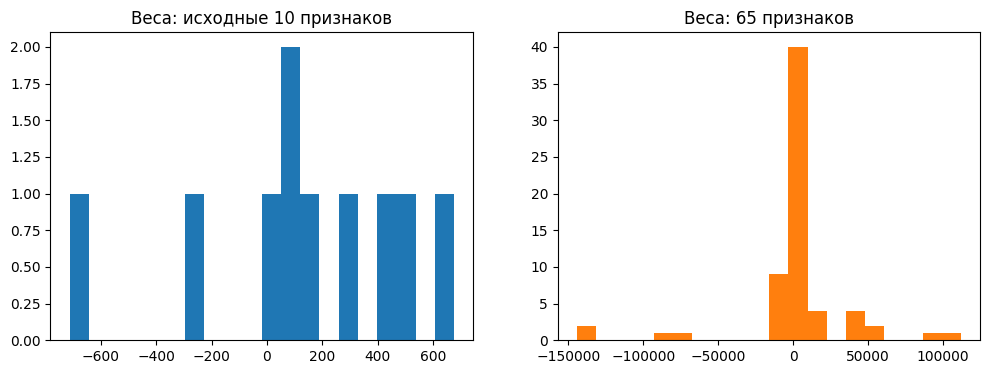

Максимальный |вес|: 713.2 vs 144273.6


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(lr.coef_, bins=20)
axes[0].set_title('Веса: исходные 10 признаков')
axes[1].hist(lr_big.coef_, bins=20, color='tab:orange')
axes[1].set_title('Веса: 65 признаков')
plt.show()

print('Максимальный |вес|:', np.abs(lr.coef_).max().round(1), 'vs', np.abs(lr_big.coef_).max().round(1))

## Регуляризация

Добавим к функции потерь штраф за большие веса:

- **L1 (Lasso):** $\;Q(w) = MSE + \alpha \sum_j |w_j|$ — зануляет часть весов (отбор признаков)
- **L2 (Ridge):** $\;Q(w) = MSE + \alpha \sum_j w_j^2$ — равномерно уменьшает веса

$\alpha$ — гиперпараметр: чем он больше, тем сильнее регуляризация.

In [12]:
from sklearn.linear_model import Lasso, Ridge

alphas = [1e-4, 1e-3, 1e-2, 0.1, 0.5, 1]
rows = []

for a in alphas:
    for name, model in [('Lasso', Lasso(alpha=a, max_iter=100_000)), ('Ridge', Ridge(alpha=a))]:
        model.fit(X_train_big, y_train)
        rows.append({
            'model': name,
            'alpha': a,
            'train MSE': mean_squared_error(y_train, model.predict(X_train_big)),
            'test MSE': mean_squared_error(y_test, model.predict(X_test_big)),
            'нулевых весов': int((np.abs(model.coef_) < 1e-8).sum()),
            'max |w|': np.abs(model.coef_).max(),
        })

res = pd.DataFrame(rows).round({'train MSE': 1, 'test MSE': 1, 'max |w|': 1})
res

,model,alpha,train MSE,test MSE,нулевых весов,max |w|
0,Lasso,0.0001,2224.9,3602.3,7,16197.8
1,Ridge,0.0001,2272.1,3440.3,0,4522.0
2,Lasso,0.0010,2294.4,3364.2,25,4502.5
3,Ridge,0.0010,2397.0,3182.2,0,2572.1
4,Lasso,0.0100,2599.1,3065.3,49,2508.8
5,Ridge,0.0100,2650.2,3061.5,0,624.8
6,Lasso,0.1000,2847.5,3161.4,58,506.1
7,Ridge,0.1000,2807.7,3173.6,0,466.2
8,Lasso,0.5000,3182.8,3517.4,61,460.5
9,Ridge,0.5000,3024.1,3493.4,0,339.0


Посмотрим на веса глазами.

In [15]:
model = Ridge(alpha=0.001)

model.fit(X_train_big, y_train)

model.coef_

array([ 4.18987609e+01, -2.52319642e+02,  5.10115097e+02,  3.22036844e+02,
       -1.01279715e+03,  7.05178840e+02,  1.92223483e+02,  1.85259959e+02,
        7.66898121e+02,  1.01286847e+02,  1.60454756e+03,  2.57212271e+03,
        2.68781550e+02,  3.15109139e+02, -3.74398086e+02, -1.09134126e+03,
        3.94963069e+02, -2.18019774e+02,  9.83168851e+02,  9.38311118e+02,
       -1.52362768e+00,  1.19171402e+03,  1.34006886e+03,  2.76979513e+02,
       -9.64422796e+02,  1.68555032e+03, -1.27065767e+03,  3.77924994e+02,
        2.89277742e+02,  1.28819664e+02,  2.00144733e+03,  1.21749402e+02,
        4.72260602e+02, -2.16904474e+02, -4.60218875e+01,  1.06179299e+02,
        6.66215973e+01, -6.47010269e+02,  2.32706381e+02, -1.94494821e+02,
        7.16139208e+02, -3.58772136e+02,  5.98366797e+02, -2.70509992e+02,
        1.24500975e+02,  4.43043440e+01,  2.05596320e+02, -7.48644250e+02,
        4.38985671e+02, -3.28336660e+02, -4.79982273e+02, -2.82287759e+02,
       -1.68911442e+02,  

In [16]:
model = Lasso(alpha=0.001)

model.fit(X_train_big, y_train)

model.coef_

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.524e+05, tolerance: 1.906e+02
  model = cd_fast.enet_coordinate_descent(


array([   42.14736554,  -257.33236524,   510.31729389,   334.15671867,
       -1158.31719468,   847.05877599,   225.43646381,   151.08104896,
         833.53713201,   111.30741908,  2125.95106091,  4197.85505221,
           0.        ,    -0.        ,     0.        , -2615.5595479 ,
         992.26264944,    -0.        ,  1471.95929234,  1318.87728491,
          -0.        ,  2111.78862365,  2090.15854772,     0.        ,
       -1534.327935  ,  3577.7801766 ,  -709.49926766,     0.        ,
           0.        ,  -123.77063734,  4424.32903813,    -0.        ,
         829.72964411,    -0.        ,    -0.        ,  -766.4327203 ,
         -10.23261805, -1692.58088676,     0.        ,    -0.        ,
        1797.07385615,    -0.        ,  1126.72886125, -1098.21685672,
           0.        ,     0.        ,    -0.        , -3063.51435636,
          -0.        ,   -92.60753476,     0.        ,  -119.85821508,
           0.        ,  3193.17130009,     0.        ,   555.86074914,
      

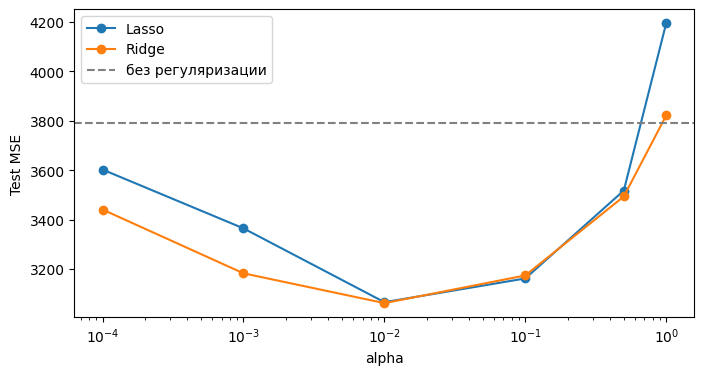

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, g in res.groupby('model'):
    ax.plot(g['alpha'], g['test MSE'], marker='o', label=name)
ax.axhline(mean_squared_error(y_test, lr_big.predict(X_test_big)), ls='--', c='gray', label='без регуляризации')
ax.set_xscale('log'); ax.set_xlabel('alpha'); ax.set_ylabel('Test MSE'); ax.legend()
plt.show()

**Выводы**

- Регуляризация возвращает качество на тесте, которое мы потеряли из-за переобучения.
- Lasso с ростом $\alpha$ зануляет всё больше весов, то есть сам отбирает признаки. Ridge веса уменьшает, но не зануляет.
- Слишком большое $\alpha$ приводит к недообучению. Подбирать $\alpha$ нужно на валидации или кросс-валидации, а не на тесте.

# 2. Кодирование категориальных признаков

Задача регрессии: по характеристикам бриллианта предсказать его цену (`price`, в долларах).

Среди признаков есть категориальные: `cut` (качество огранки), `color` (цвет), `clarity` (чистота).

In [18]:
import seaborn as sns

data = sns.load_dataset('diamonds')
data.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [19]:
X = data.drop(columns='price')
y = data['price'].astype(float)

num_cols = X.select_dtypes('number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()

print('Числовые:', num_cols)
print('Категориальные:', cat_cols)

Числовые: ['carat', 'depth', 'table', 'x', 'y', 'z']
Категориальные: ['cut', 'color', 'clarity']


In [20]:
X[cat_cols].nunique()

,0
cut,5
color,7
clarity,8


Модели работают только с числами, поэтому категории нужно закодировать.

## One-Hot Encoding

Признак с $k$ категориями превращается в $k$ бинарных столбцов: 1 — объект относится к этой категории, 0 — нет.

In [21]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(sparse_output=False)
ohe.set_output(transform='pandas')

ohe.fit_transform(X[['cut']]).head()

,cut_Fair,cut_Good,cut_Ideal,cut_Premium,cut_Very Good
0,0.0,0.0,1.0,0.0,0.0
1,0.0,0.0,0.0,1.0,0.0
2,0.0,1.0,0.0,0.0,0.0
3,0.0,0.0,0.0,1.0,0.0
4,0.0,1.0,0.0,0.0,0.0


**Вопрос:** нужно ли удалять один из столбцов после такого кодирования?

Сумма всех $k$ столбцов всегда равна 1, то есть столбцы линейно зависимы с константой (dummy trap). Для линейной модели без регуляризации один столбец лучше удалить: `OneHotEncoder(drop='first')`. С регуляризацией проблема менее острая.

Минус OHE: если категорий много, признаков становится очень много.

In [22]:
ohe_drop = OneHotEncoder(drop='first', sparse_output=False)
ohe_drop.set_output(transform='pandas')

ohe_drop.fit_transform(X[['cut']]).head()

,cut_Good,cut_Ideal,cut_Premium,cut_Very Good
0,0.0,1.0,0.0,0.0
1,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0
3,0.0,0.0,1.0,0.0
4,1.0,0.0,0.0,0.0


## Mean target encoding

Заменим категорию на среднее значение таргета в этой категории, то есть на среднюю цену бриллиантов с такой огранкой. Признак остаётся один, сколько бы ни было категорий.

$$\text{code}(c) = \frac{mean(target_c)\cdot n_c + \alpha \cdot globalMean}{n_c + \alpha}$$

где $n_c$ — число объектов категории $c$, $\alpha$ — сила сглаживания.

In [26]:
def mean_target_encoding(x, target, alpha=10):
    global_mean = target.mean()
    stats = target.groupby(x, observed=True).agg(['mean', 'count'])
    codes = (stats['mean'] * stats['count'] + alpha * global_mean) / (stats['count'] + alpha)
    return x.map(codes), codes

encoded, codes = mean_target_encoding(X['cut'], y)
codes.sort_values()

,0
cut,
Ideal,3457.762395
Good,3928.872457
Very Good,3981.719401
Fair,4356.128393
Premium,4583.785668


Интересно: у лучшей огранки `Ideal` средняя цена самая низкая. Дело в том, что цена сильнее всего зависит от размера (`carat`), а бриллианты с идеальной огранкой в среднем меньше. Target encoding видит только среднее по категории и не учитывает другие признаки. Поэтому его значения нужно интерпретировать осторожно.

**Важно:** target encoding использует таргет, поэтому легко получить утечку и переобучение.

- Значения считаем **только по обучающей выборке**, а потом применяем к тесту.
- Внутри трейна значения лучше считать на кросс-валидации: код объекта вычисляется по другим фолдам, без его собственного таргета.

Класс `TargetEncoder` из sklearn (версия 1.3+) делает это сам (для регрессии указываем `target_type='continuous'`): `fit_transform` считает коды на кросс-валидации, а `transform` для новых данных использует статистики по всему трейну.

In [24]:
from sklearn.preprocessing import TargetEncoder

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42)

te = TargetEncoder(target_type='continuous', cv=5)
te.set_output(transform='pandas')

X_tr_te = te.fit_transform(X_tr[['cut']], y_tr)   # коды на кросс-валидации
X_te_te = te.transform(X_te[['cut']])             # коды по всему трейну

pd.DataFrame({'cut': X_te['cut'].values,
              'encoded': X_te_te['cut'].round(1).values}).drop_duplicates().sort_values('encoded')

,cut,encoded
0,Ideal,3466.1
14,Good,3947.2
1,Very Good,3994.3
5,Fair,4446.9
3,Premium,4584.0


# 3. Сравнение в пайплайне

Соберём пайплайны: кодирование категорий + масштабирование числовых признаков + линейная регрессия. Сравним RMSE на кросс-валидации (чем меньше, тем лучше).

In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold

def make_pipe(encoder):
    prep = ColumnTransformer([
        ('num', StandardScaler(), num_cols),
        ('cat', encoder, cat_cols),
    ])
    return Pipeline([('prep', prep), ('model', LinearRegression())])

pipes = {
    'One-Hot':           make_pipe(OneHotEncoder(handle_unknown='ignore')),
    'One-Hot (drop)':    make_pipe(OneHotEncoder(drop='first', handle_unknown='ignore')),
    'Target encoding':   make_pipe(TargetEncoder(target_type='continuous')),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)   # данные отсортированы, поэтому перемешиваем

for name, pipe in pipes.items():
    scores = -cross_val_score(pipe, X, y, cv=cv, scoring='neg_root_mean_squared_error')
    print(f'{name:18s} RMSE = {scores.mean():.1f} ± {scores.std():.1f}')

One-Hot            RMSE = 1130.9 ± 24.6
One-Hot (drop)     RMSE = 1130.9 ± 24.6
Target encoding    RMSE = 1288.6 ± 28.2


**Выводы**

- One-Hot подходит, когда категорий немного: признаки понятные, а модель видит каждую категорию отдельно. В нашем датасете категорий всего 5–8, поэтому One-Hot здесь выигрывает.
- Mean target encoding компактен и хорошо работает при большом числе категорий, но требует аккуратности: сглаживания и подсчёта на кросс-валидации, иначе модель переобучится на таргет.
- Оба кодировщика удобно встраивать в `Pipeline`. Тогда всё, что зависит от данных (категории, средние таргета, параметры масштабирования), считается только на обучающей части каждого фолда.